<a href="https://colab.research.google.com/github/Najia-Talpur/Applied-Data-Science-1/blob/main/EV_ChargeSense_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import numpy as np
import pandas as pd
import sqlite3
import random
from datetime import datetime, timedelta

In [31]:
conn = sqlite3.connect("ev_chargesense.db")
conn.execute("PRAGMA foreign_keys = ON")
cursor = conn.cursor()

cursor.executescript("""
DROP TABLE IF EXISTS maintenance;
DROP TABLE IF EXISTS charging_sessions;
DROP TABLE IF EXISTS chargers;
DROP TABLE IF EXISTS stations;

CREATE TABLE stations (
    station_id INTEGER PRIMARY KEY,
    station_name TEXT NOT NULL,
    town TEXT NOT NULL,
    station_type TEXT NOT NULL
);

CREATE TABLE chargers (
    station_id INTEGER NOT NULL,
    charger_number INTEGER NOT NULL,
    charger_type TEXT NOT NULL,
    power_kw REAL NOT NULL CHECK (power_kw > 0),
    status TEXT NOT NULL CHECK (status IN ('Available', 'Under Maintenance')),
    PRIMARY KEY (station_id, charger_number),
    FOREIGN KEY (station_id) REFERENCES stations(station_id)
);

CREATE TABLE charging_sessions (
    session_id INTEGER PRIMARY KEY,
    station_id INTEGER NOT NULL,
    charger_number INTEGER NOT NULL,
    vehicle_type TEXT NOT NULL,
    charging_start TEXT NOT NULL,
    duration_minutes INTEGER NOT NULL CHECK (duration_minutes > 0),
    energy_kwh REAL NOT NULL CHECK (energy_kwh >= 0),
    temperature_c REAL NOT NULL,
    customer_rating INTEGER NOT NULL CHECK (customer_rating BETWEEN 1 AND 5),
    payment_method TEXT NOT NULL,
    FOREIGN KEY (station_id, charger_number)
        REFERENCES chargers(station_id, charger_number)
);
""")

conn.commit()

In [32]:
station_details = [
    ("Northgate Charge Hub", "Leeds", "Urban"),
    ("Riverside EV Point", "Bristol", "Retail"),
    ("Central Market Chargers", "Manchester", "Retail"),
    ("Airport Link Hub", "London", "Highway"),
    ("Meadow Business Park", "Milton Keynes", "Workplace"),
    ("Harbour Road EV", "Southampton", "Urban"),
    ("Station Quarter Charge", "Birmingham", "Urban"),
    ("Parkway Rapid Hub", "Nottingham", "Highway"),
    ("University EV Point", "Oxford", "Workplace"),
    ("Westfield Charge Plaza", "Glasgow", "Retail"),
    ("Green Lane Chargers", "Cardiff", "Urban"),
    ("Coastal Mobility Hub", "Newcastle", "Highway")
]

station_rows = [
    (i, name, town, station_type)
    for i, (name, town, station_type) in enumerate(station_details, start=1)
]

cursor.executemany(
    "INSERT INTO stations VALUES (?, ?, ?, ?)",
    station_rows
)
conn.commit()

In [33]:
print(len(station_rows))

12


In [34]:
charger_rows = []

for station_id in range(1, len(station_details) + 1):
    number_of_chargers = random.randint(4, 6)

    for charger_number in range(1, number_of_chargers + 1):
        charger_type = random.choice(["Slow", "Fast", "Rapid"])

        if charger_type == "Slow":
            power_kw = random.choice([3.7, 7.4, 11.0])
        elif charger_type == "Fast":
            power_kw = random.choice([22.0, 43.0, 50.0])
        else:
            power_kw = random.choice([50.0, 100.0, 150.0])

        status = random.choices(
            ["Available", "Under Maintenance"],
            weights=[93, 7]
        )[0]

        charger_rows.append((
            station_id, charger_number, charger_type, power_kw, status
        ))

cursor.executemany(
    "INSERT INTO chargers VALUES (?, ?, ?, ?, ?)",
    charger_rows
)
conn.commit()

available_chargers = [
    row for row in charger_rows if row[4] == "Available"
]

In [35]:
print(len(charger_rows))

58


In [36]:
vehicle_types = ["Hatchback", "Sedan", "SUV", "Van"]
payment_methods = ["Contactless", "App", "Subscription"]
start_date = datetime(2025, 1, 1)
session_rows = []

for session_id in range(1, 1501):
    station_id, charger_number, charger_type, power_kw, status = random.choice(
        available_chargers
    )

    duration_minutes = random.randint(15, 240)
    energy_kwh = round(
        min(power_kw * duration_minutes / 60 * random.uniform(0.45, 0.85), 80),
        2
    )

    charging_time = start_date + timedelta(
        days=random.randint(0, 364),
        minutes=random.randint(0, 1439)
    )

    temperature_c = round(random.uniform(-5, 32), 1)
    customer_rating = random.choices(
        [1, 2, 3, 4, 5],
        weights=[4, 8, 18, 40, 30]
    )[0]

    session_rows.append((
        session_id,
        station_id,
        charger_number,
        random.choice(vehicle_types),
        charging_time.strftime("%Y-%m-%d %H:%M:%S"),
        duration_minutes,
        energy_kwh,
        temperature_c,
        customer_rating,
        random.choice(payment_methods)
    ))

cursor.executemany("""
    INSERT INTO charging_sessions
    VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", session_rows)

conn.commit()

In [37]:
print(len(session_rows))

1500


Checking Data

In [38]:
for table_name in ["stations", "chargers", "charging_sessions"]:
    result = pd.read_sql_query(
        f"SELECT COUNT(*) AS row_count FROM {table_name}",
        conn
    )
    print(f"{table_name}: {result.loc[0, 'row_count']} rows")

sessions = pd.read_sql_query(
    "SELECT * FROM charging_sessions LIMIT 5",
    conn
)
display(sessions)

stations: 12 rows
chargers: 58 rows
charging_sessions: 1500 rows


,session_id,station_id,charger_number,vehicle_type,charging_start,duration_minutes,energy_kwh,temperature_c,customer_rating,payment_method
0,1,1,2,Hatchback,2025-08-05 14:35:00,209,80.00,30.3,5,App
1,2,3,4,Sedan,2025-09-03 07:27:00,49,28.39,23.1,4,Contactless
2,3,5,1,Sedan,2025-07-07 15:27:00,164,49.79,21.1,3,Subscription
3,4,6,3,Hatchback,2025-07-21 19:05:00,74,13.34,23.6,3,Contactless
4,5,8,2,Sedan,2025-10-14 12:34:00,227,80.00,29.1,4,Contactless


In [39]:
import matplotlib.pyplot as plt

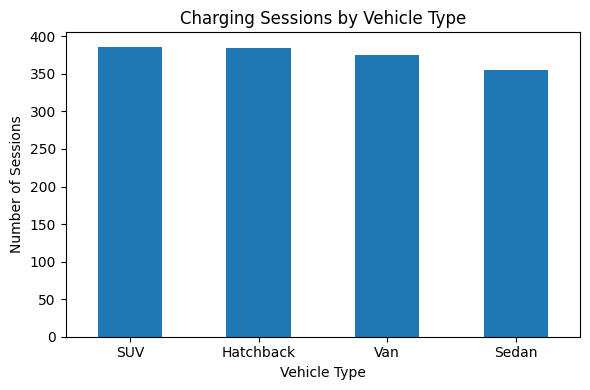

In [40]:
sessions = pd.read_sql_query(
    "SELECT * FROM charging_sessions", conn)

vehicle_counts = sessions["vehicle_type"].value_counts()

plt.figure(figsize=(6, 4))
vehicle_counts.plot(kind="bar")

plt.title("Charging Sessions by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

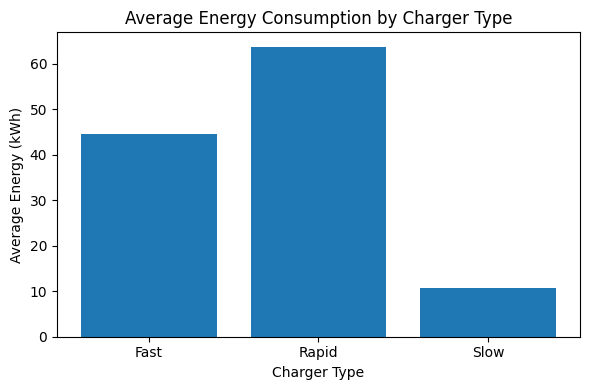

In [41]:
energy_data = pd.read_sql_query("""
    SELECT c.charger_type,
           AVG(s.energy_kwh) AS average_energy
    FROM charging_sessions s
    JOIN chargers c
    ON s.station_id = c.station_id
    AND s.charger_number = c.charger_number
    GROUP BY c.charger_type
""", conn)

plt.figure(figsize=(6, 4))
plt.bar(energy_data["charger_type"], energy_data["average_energy"])

plt.title("Average Energy Consumption by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Average Energy (kWh)")
plt.tight_layout()
plt.show()

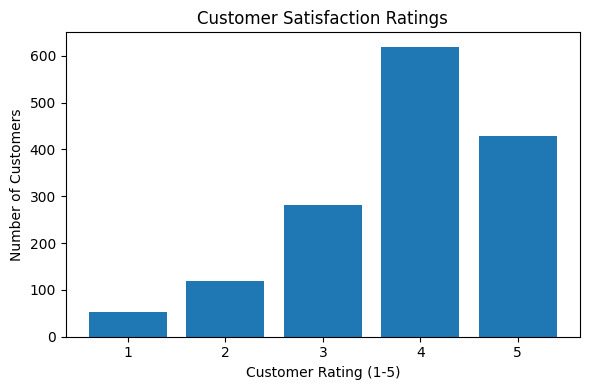

In [42]:
ratings = sessions["customer_rating"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(ratings.index, ratings.values)

plt.title("Customer Satisfaction Ratings")
plt.xlabel("Customer Rating (1-5)")
plt.ylabel("Number of Customers")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

Download Database

In [43]:
conn.commit()
conn.close()
print("Database saved as ev_chargesense.db")

try:
    from google.colab import files
    files.download("ev_chargesense.db")
except ImportError:
    print("Run this notebook in Google Colab to download the database file.")

Database saved as ev_chargesense.db


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>